In [6]:
from google.colab import drive
drive.mount('/content/drive')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [7]:
# clean data dir
! rm -rf /content/data

In [8]:
# move data from to colab space
! mkdir /content/data
!cp /content/drive/MyDrive/deeplearning-project/data/dataset.csv /content/data/dataset.csv
!unzip -q "/content/drive/MyDrive/deeplearning-project/data/Archive.zip" -d /content/data

In [9]:
# Install requirements
!pip install -q transformers datasets torchvision mlflow scikit-learn tqdm

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 491.2/491.2 kB 35.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 363.4/363.4 MB 2.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.8/13.8 MB 117.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.6/24.6 MB 87.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 883.7/883.7 kB 50.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 664.8/664.8 MB 1.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 211.5/211.5 MB 5.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.3/56.3 MB 35.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 127.9/127.9 MB 15.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 207.5/207.5 MB 3.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 21.1/21.1 MB 99.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 28.2/28.2 MB 76.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

In [10]:
import os

from pathlib import Path

import matplotlib.pyplot as plt
import mlflow
import mlflow.pytorch

import pandas as pd
import seaborn as sns
import torch
import torch.nn as nn
import torch.optim as optim

from datasets import load_dataset

from sklearn.metrics import classification_report

from torch.utils.data import DataLoader
from torchvision import  models, datasets, transforms
from torchvision.datasets import ImageFolder

from tqdm import tqdm


In [11]:
# define paths
root_data = Path("/content/data")
dataset_csv_path = root_data / "dataset.csv"

train_data_path = root_data / "train"
val_data_path = root_data / "val"

In [12]:
# Load the dataset
dataset_df = pd.read_csv(dataset_csv_path)

dataset_df.head()

,image_path,image_type,label
0,/Users/seifmostafa/Documents/porto-uni/deep-le...,real,0
1,/Users/seifmostafa/Documents/porto-uni/deep-le...,real,0
2,/Users/seifmostafa/Documents/porto-uni/deep-le...,real,0
3,/Users/seifmostafa/Documents/porto-uni/deep-le...,real,0
4,/Users/seifmostafa/Documents/porto-uni/deep-le...,real,0


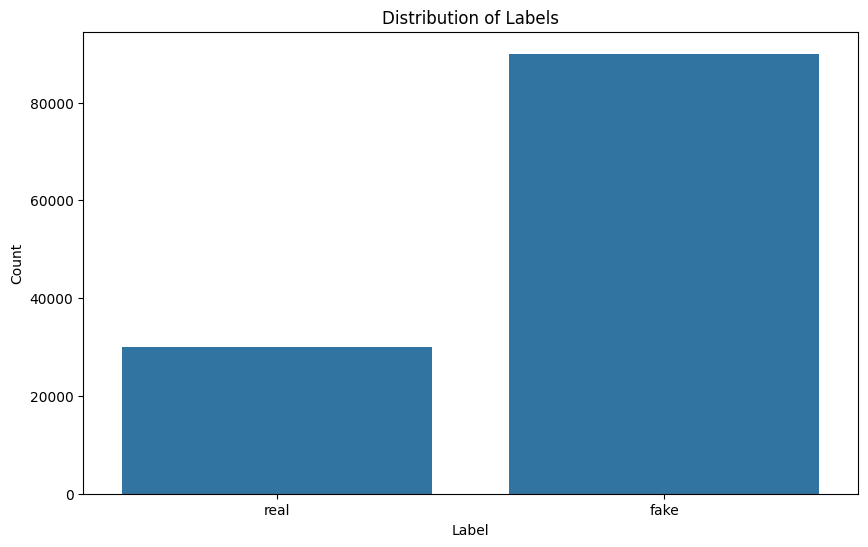

In [13]:
# Assuming 'label' column contains the labels for distribution plotting
# Replace 'label' with your actual column name if different
plt.figure(figsize=(10, 6))
sns.countplot(x='image_type', data=dataset_df) # Replace 'label' if necessary
plt.title('Distribution of Labels')
plt.xlabel('Label')
plt.ylabel('Count')
plt.show()


In [14]:
train_fake_count = len(list((train_data_path / "fake").glob("*")))
train_real_count = len(list((train_data_path / "real").glob("*")))

print(f"Number of images in train/fake: {train_fake_count}")
print(f"Number of images in train/real: {train_real_count}")

val_fake_count = len(list((val_data_path / "fake").glob("*")))
val_real_count = len(list((val_data_path / "real").glob("*")))

print(f"Number of images in val/fake: {val_fake_count}")
print(f"Number of images in val/real: {val_real_count}")


Number of images in train/fake: 72000
Number of images in train/real: 24000
Number of images in val/fake: 18000
Number of images in val/real: 6000


In [15]:

device = (
    "cuda" if torch.cuda.is_available()
    else "mps" if torch.backends.mps.is_available()
    else "cpu"
)
print(f"Using device: {device}")

Using device: cuda


In [16]:
# hyperparams
epochs = 20
learning_rate = 1e-4
batch_size = 32
num_classes = 2

In [17]:
# get Resnet50 model
def get_model(num_classes=2):
    model = models.resnet50(pretrained=True)
    for param in model.parameters():
        param.requires_grad = False  # Freeze backbone
    model.fc = nn.Linear(model.fc.in_features, num_classes)  # Replace classifier head
    return model

In [18]:
# initialise loaders

transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5]*3, std=[0.5]*3),
])

train_dataset = datasets.ImageFolder(root=train_data_path, transform=transform)
val_dataset = datasets.ImageFolder(root=val_data_path, transform=transform)
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)

In [25]:
def train_model(model, epochs, lr):
    # Compute class weights for imbalanced datasets
    labels = [label for _, label in train_dataset.samples]
    class_counts = torch.bincount(torch.tensor(labels))
    class_weights = 1.0 / class_counts.float()
    class_weights = class_weights.to(device)

    # Loss and optimizer
    criterion = nn.CrossEntropyLoss(weight=class_weights)
    optimizer = optim.Adam(model.parameters(), lr=lr)

    model = model.to(device)

    with mlflow.start_run():
        # Log parameters
        mlflow.log_params({
            "model": "resnet50",
            "epochs": epochs,
            "learning_rate": lr,
            "batch_size": batch_size,
        })
        max_accuracy = 0.0

        for epoch in range(epochs):
            model.train()
            total_train_loss = 0.0

            train_loop = tqdm(train_loader, desc=f"Epoch {epoch+1}/{epochs} [Train]", leave=False)
            for images, labels in train_loop:
                images, labels = images.to(device), labels.to(device)

                optimizer.zero_grad()
                outputs = model(images)
                loss = criterion(outputs, labels)
                loss.backward()
                optimizer.step()

                total_train_loss += loss.item()
                train_loop.set_postfix(loss=loss.item())

            avg_train_loss = total_train_loss / len(train_loader)
            mlflow.log_metric("train_loss", avg_train_loss, step=epoch)

            # Validation
            model.eval()
            total_val_loss = 0.0
            correct = 0
            total = 0
            all_preds = []
            all_labels = []



            val_loop = tqdm(val_loader, desc=f"Epoch {epoch+1}/{epochs} [Val]", leave=False)
            with torch.no_grad():
                for images, labels in val_loop:
                    images, labels = images.to(device), labels.to(device)
                    outputs = model(images)
                    loss = criterion(outputs, labels)

                    total_val_loss += loss.item()
                    preds = torch.argmax(outputs, dim=1)
                    correct += (preds == labels).sum().item()
                    total += labels.size(0)
                    all_preds.extend(preds.cpu().numpy())
                    all_labels.extend(labels.cpu().numpy())
                    val_loop.set_postfix(loss=loss.item())

            avg_val_loss = total_val_loss / len(val_loader)
            val_accuracy = 100 * correct / total

            mlflow.log_metric("val_loss", avg_val_loss, step=epoch)
            mlflow.log_metric("val_accuracy", val_accuracy, step=epoch)


            target_names = train_dataset.classes
            report = classification_report(all_labels, all_preds, target_names=target_names, output_dict=True)
            print(report)

            for label, metrics in report.items():
                if isinstance(metrics, dict):
                    for metric_name, value in metrics.items():
                        mlflow.log_metric(f"{label}_{metric_name}", value, step=epoch)
                else:
                    mlflow.log_metric(f"{label}", metrics, step=epoch)

            print(f"[Epoch {epoch+1}] Train Loss: {avg_train_loss:.4f} | Val Loss: {avg_val_loss:.4f} | Val Acc: {val_accuracy:.2f}%")
            if val_accuracy > max_accuracy:
                max_accuracy = val_accuracy
                print(f"New best accuracy: {max_accuracy:.2f}%")
                # save model
                torch.save(model.state_dict(), "resnet_finetuned.pth")
                mlflow.pytorch.log_model(model, artifact_path="model")

In [ ]:
model = get_model(num_classes=2)

In [26]:
train_model(model, epochs=10, lr=learning_rate)

{'fake': {'precision': 0.8903470202259351, 'recall': 0.7312222222222222, 'f1-score': 0.802977152792606, 'support': 18000.0}, 'real': {'precision': 0.47510035803406747, 'recall': 0.7298333333333333, 'f1-score': 0.5755405138989288, 'support': 6000.0}, 'accuracy': 0.730875, 'macro avg': {'precision': 0.6827236891300013, 'recall': 0.7305277777777778, 'f1-score': 0.6892588333457674, 'support': 24000.0}, 'weighted avg': {'precision': 0.7865353546779682, 'recall': 0.730875, 'f1-score': 0.7461179930691866, 'support': 24000.0}}
[Epoch 1] Train Loss: 0.5312 | Val Loss: 0.5184 | Val Acc: 73.09%
New best accuracy: 73.09%


2025/04/06 16:26:34 WARNING mlflow.utils.requirements_utils: Found torch version (2.6.0+cu124) contains a local version label (+cu124). MLflow logged a pip requirement for this package as 'torch==2.6.0' without the local version label to make it installable from PyPI. To specify pip requirements containing local version labels, please use `conda_env` or `pip_requirements`.
2025/04/06 16:26:41 WARNING mlflow.utils.requirements_utils: Found torchvision version (0.21.0+cu124) contains a local version label (+cu124). MLflow logged a pip requirement for this package as 'torchvision==0.21.0' without the local version label to make it installable from PyPI. To specify pip requirements containing local version labels, please use `conda_env` or `pip_requirements`.
2025/04/06 16:26:41 WARNING mlflow.models.model: Model logged without a signature and input example. Please set `input_example` parameter when logging the model to auto infer the model signature.


{'fake': {'precision': 0.8961167800453514, 'recall': 0.7025555555555556, 'f1-score': 0.7876183358246138, 'support': 18000.0}, 'real': {'precision': 0.45853559870550165, 'recall': 0.7556666666666667, 'f1-score': 0.5707452165156093, 'support': 6000.0}, 'accuracy': 0.7158333333333333, 'macro avg': {'precision': 0.6773261893754265, 'recall': 0.7291111111111112, 'f1-score': 0.6791817761701116, 'support': 24000.0}, 'weighted avg': {'precision': 0.786721484710389, 'recall': 0.7158333333333333, 'f1-score': 0.7334000559973627, 'support': 24000.0}}
[Epoch 2] Train Loss: 0.5304 | Val Loss: 0.5368 | Val Acc: 71.58%


{'fake': {'precision': 0.8920046508446755, 'recall': 0.7245555555555555, 'f1-score': 0.7996076147267098, 'support': 18000.0}, 'real': {'precision': 0.47137221452180406, 'recall': 0.7368333333333333, 'f1-score': 0.574939853046362, 'support': 6000.0}, 'accuracy': 0.727625, 'macro avg': {'precision': 0.6816884326832398, 'recall': 0.7306944444444444, 'f1-score': 0.6872737338865359, 'support': 24000.0}, 'weighted avg': {'precision': 0.7868465417639575, 'recall': 0.727625, 'f1-score': 0.7434406743066229, 'support': 24000.0}}
[Epoch 3] Train Loss: 0.5309 | Val Loss: 0.5222 | Val Acc: 72.76%


{'fake': {'precision': 0.8902959301144444, 'recall': 0.7303888888888889, 'f1-score': 0.8024536881618701, 'support': 18000.0}, 'real': {'precision': 0.47438535687208927, 'recall': 0.73, 'f1-score': 0.5750672881244666, 'support': 6000.0}, 'accuracy': 0.7302916666666667, 'macro avg': {'precision': 0.6823406434932668, 'recall': 0.7301944444444444, 'f1-score': 0.6887604881431684, 'support': 24000.0}, 'weighted avg': {'precision': 0.7863182868038555, 'recall': 0.7302916666666667, 'f1-score': 0.7456070881525193, 'support': 24000.0}}
[Epoch 4] Train Loss: 0.5279 | Val Loss: 0.5190 | Val Acc: 73.03%


...

{'fake': {'precision': 0.9053501004539029, 'recall': 0.6759444444444445, 'f1-score': 0.7740068068322784, 'support': 18000.0}, 'real': {'precision': 0.4476848783259161, 'recall': 0.788, 'f1-score': 0.570980013284222, 'support': 6000.0}, 'accuracy': 0.7039583333333334, 'macro avg': {'precision': 0.6765174893899095, 'recall': 0.7319722222222222, 'f1-score': 0.6724934100582503, 'support': 24000.0}, 'weighted avg': {'precision': 0.7909337949219062, 'recall': 0.7039583333333334, 'f1-score': 0.7232501084452643, 'support': 24000.0}}
[Epoch 7] Train Loss: 0.5277 | Val Loss: 0.5524 | Val Acc: 70.40%


{'fake': {'precision': 0.9026979856010472, 'recall': 0.6896111111111111, 'f1-score': 0.7818966331769078, 'support': 18000.0}, 'real': {'precision': 0.4548736462093863, 'recall': 0.777, 'f1-score': 0.5738199273801464, 'support': 6000.0}, 'accuracy': 0.7114583333333333, 'macro avg': {'precision': 0.6787858159052167, 'recall': 0.7333055555555555, 'f1-score': 0.6778582802785271, 'support': 24000.0}, 'weighted avg': {'precision': 0.7907419007531319, 'recall': 0.7114583333333333, 'f1-score': 0.7298774567277175, 'support': 24000.0}}
[Epoch 8] Train Loss: 0.5276 | Val Loss: 0.5446 | Val Acc: 71.15%


{'fake': {'precision': 0.8871352785145888, 'recall': 0.7432222222222222, 'f1-score': 0.8088270858524789, 'support': 18000.0}, 'real': {'precision': 0.4818385650224215, 'recall': 0.7163333333333334, 'f1-score': 0.5761394101876676, 'support': 6000.0}, 'accuracy': 0.7365, 'macro avg': {'precision': 0.6844869217685052, 'recall': 0.7297777777777779, 'f1-score': 0.6924832480200732, 'support': 24000.0}, 'weighted avg': {'precision': 0.785811100141547, 'recall': 0.7365, 'f1-score': 0.750655166936276, 'support': 24000.0}}
[Epoch 9] Train Loss: 0.5262 | Val Loss: 0.5108 | Val Acc: 73.65%
New best accuracy: 73.65%


2025/04/06 18:00:04 WARNING mlflow.utils.requirements_utils: Found torch version (2.6.0+cu124) contains a local version label (+cu124). MLflow logged a pip requirement for this package as 'torch==2.6.0' without the local version label to make it installable from PyPI. To specify pip requirements containing local version labels, please use `conda_env` or `pip_requirements`.
2025/04/06 18:00:11 WARNING mlflow.utils.requirements_utils: Found torchvision version (0.21.0+cu124) contains a local version label (+cu124). MLflow logged a pip requirement for this package as 'torchvision==0.21.0' without the local version label to make it installable from PyPI. To specify pip requirements containing local version labels, please use `conda_env` or `pip_requirements`.
2025/04/06 18:00:11 WARNING mlflow.models.model: Model logged without a signature and input example. Please set `input_example` parameter when logging the model to auto infer the model signature.


{'fake': {'precision': 0.8985179957657022, 'recall': 0.7073333333333334, 'f1-score': 0.7915449176251166, 'support': 18000.0}, 'real': {'precision': 0.46408952187182095, 'recall': 0.7603333333333333, 'f1-score': 0.5763739734680986, 'support': 6000.0}, 'accuracy': 0.7205833333333334, 'macro avg': {'precision': 0.6813037588187616, 'recall': 0.7338333333333333, 'f1-score': 0.6839594455466076, 'support': 24000.0}, 'weighted avg': {'precision': 0.789910877292232, 'recall': 0.7205833333333334, 'f1-score': 0.7377521815858621, 'support': 24000.0}}
[Epoch 10] Train Loss: 0.5276 | Val Loss: 0.5331 | Val Acc: 72.06%


In [27]:
# save mlrun to googledrive

# Save the mlflow run to Google Drive
!mkdir -p /content/drive/MyDrive/deeplearning-project/mlruns
!cp -r /content/mlruns /content/drive/MyDrive/deeplearning-project/mlruns
